In [ ]:
pip install tensorflow

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error

In [ ]:
from google.colab import files

uploaded = files.upload()

TypeError: 'NoneType' object is not subscriptable

In [ ]:
df_clean = pd.read_csv("prediction_traffic_lstm_feature_engineering.csv")

# to convert the string and set as index
df_clean['date_time'] = pd.to_datetime(df_clean['date_time'])
df_clean = df_clean.set_index('date_time').sort_index()

In [ ]:
val_start = df_clean.index.get_loc("2016-10-01 09:00:00")
test_start = df_clean.index.get_loc("2017-10-02 09:00:00")
n = len(df_clean)

print(f"Validation data starts at: {val_start}")
print(f"Testing data starts at: {test_start}")
print(f"Total number of data: {n}")

In [ ]:
target_column = "traffic_volume"
feature_columns = [col for col in df_clean.columns if col not in ["traffic_volume", "date_time"]]

In [ ]:
# Splitting data
train = df_clean.iloc[:val_start]
val = df_clean.iloc[val_start: test_start]
test = df_clean.iloc[test_start: n]

X_train, y_train = train[feature_columns].to_numpy(), train[target_column].to_numpy()
X_val, y_val = val[feature_columns].to_numpy(), val[target_column].to_numpy()
X_test, y_test = test[feature_columns].to_numpy(), test[target_column].to_numpy()

In [ ]:
# Scaling using min-max scaler
from sklearn.preprocessing import MinMaxScaler

scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

# for y -> it is in 1D, but min-max need 2D

X_train_scaled = scaler_X.fit_transform(X_train)
y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1))

X_val_scaled = scaler_X.transform(X_val)
y_val_scaled = scaler_y.transform(y_val.reshape(-1, 1))

X_test_scaled = scaler_X.transform(X_test)
y_test_scaled = scaler_y.transform(y_test.reshape(-1, 1))

In [ ]:
# Let model refers to the last 24 hours
SEQ_LENGTH = 24

In [ ]:
def make_sequence(X, y, seq_length):
  Xs = []
  ys = []

  for i in range(seq_length, len(X)):
    Xs.append(X[i - seq_length: i])
    ys.append(y[i])

  return np.array(Xs), np.array(ys)

In [ ]:
X_train_seq, y_train_seq = make_sequence(X_train_scaled, y_train_scaled, SEQ_LENGTH)
X_val_seq, y_val_seq = make_sequence(X_val_scaled, y_val_scaled, SEQ_LENGTH)
X_test_seq, y_test_seq = make_sequence(X_test_scaled, y_test_scaled, SEQ_LENGTH)

In [ ]:
print(f"Train: {X_train_seq.shape}, {y_train_seq.shape}")
print(f"Validation: {X_val_seq.shape}, {y_val_seq.shape}")
print(f"Test: {X_test_seq.shape}, {y_test_seq.shape}")

In [ ]:
model_lstm = Sequential([
    LSTM(512, activation = "relu", return_sequences = True, input_shape = (X_train_seq.shape[1], X_train_seq.shape[2])),
    LSTM(512, activation = "relu", return_sequences = False),
    Dense(512, activation = "relu"),
    Dense(512, activation = "relu"),
    Dense(1) # Provide 1 value for prediction
])

model_lstm.compile(optimizer = "adam", loss = "mean_squared_error", metrics = ["MAE"])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
model_lstm.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 512)        │     1,112,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 512)            │     2,099,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,737,089 (14.26 MB)

 Trainable params: 3,737,089 (14.26 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stop = EarlyStopping(
    monitor = "val_loss",
    patience = 3
)

history = model_lstm.fit(
    X_train_seq, y_train_seq,
    validation_data = (X_val_seq, y_val_seq),
    epochs = 30,
    batch_size = 64,
    callbacks = [early_stop],
    shuffle = False
)

Epoch 1/30
362/362 ━━━━━━━━━━━━━━━━━━━━ 20s 40ms/step - MAE: 0.2119 - loss: 0.0760 - val_MAE: 0.1225 - val_loss: 0.0233
Epoch 2/30
362/362 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - MAE: 0.0970 - loss: 0.0181 - val_MAE: 0.0958 - val_loss: 0.0172
Epoch 3/30
362/362 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - MAE: 0.0847 - loss: 0.0149 - val_MAE: 0.0738 - val_loss: 0.0098
Epoch 4/30
362/362 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - MAE: 0.0767 - loss: 0.0126 - val_MAE: 0.0607 - val_loss: 0.0071
Epoch 5/30
362/362 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - MAE: 0.0721 - loss: 0.0111 - val_MAE: 0.0620 - val_loss: 0.0073
Epoch 6/30
362/362 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - MAE: 0.0671 - loss: 0.0097 - val_MAE: 0.0604 - val_loss: 0.0070
Epoch 7/30
362/362 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - MAE: 0.0641 - loss: 0.0088 - val_MAE: 0.0656 - val_loss: 0.0079
Epoch 8/30
362/362 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - MAE: 0.0597 - loss: 0.0078 - val_MAE: 0.0575 - val_loss: 0.0064
Epoch 9/30
362/362 ━━━━━━━━━━━━━━━━━━━━ 

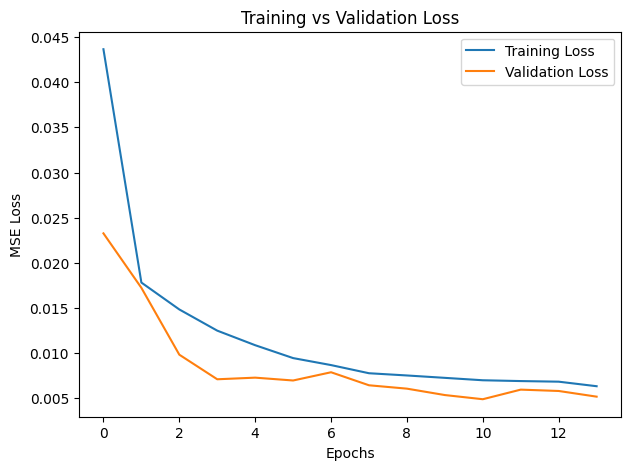

In [ ]:
plt.figure(figsize = (7, 5))
plt.plot(history.history["loss"], label = "Training Loss")
plt.plot(history.history["val_loss"], label = "Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

In [ ]:
model_xgb = xgb.XGBRegressor(
    objective = "reg:squarederror",
    n_estimators = 200,
    learning_rate = 0.1,
    max_depth = 5,
    random_state = 42,
    eval_metric = "mae"
)

In [ ]:
model_xgb.fit(
    X_train_seq.reshape(X_train_seq.shape[0], -1), y_train_seq,
    eval_set = [(X_val_seq.reshape(X_val_seq.shape[0], -1), y_val_seq)]
)

[0]	validation_0-mae:0.21511
[1]	validation_0-mae:0.19535
[2]	validation_0-mae:0.17773
[3]	validation_0-mae:0.16210
[4]	validation_0-mae:0.14826
[5]	validation_0-mae:0.13570
[6]	validation_0-mae:0.12462
[7]	validation_0-mae:0.11483
[8]	validation_0-mae:0.10606
[9]	validation_0-mae:0.09849
[10]	validation_0-mae:0.09184
[11]	validation_0-mae:0.08571
[12]	validation_0-mae:0.08041
[13]	validation_0-mae:0.07559
[14]	validation_0-mae:0.07132
[15]	validation_0-mae:0.06768
[16]	validation_0-mae:0.06456
[17]	validation_0-mae:0.06169
[18]	validation_0-mae:0.05912
[19]	validation_0-mae:0.05680
[20]	validation_0-mae:0.05485
[21]	validation_0-mae:0.05303
[22]	validation_0-mae:0.05150
[23]	validation_0-mae:0.05003
[24]	validation_0-mae:0.04870
[25]	validation_0-mae:0.04774
[26]	validation_0-mae:0.04705
[27]	validation_0-mae:0.04637
[28]	validation_0-mae:0.04550
[29]	validation_0-mae:0.04447
[30]	validation_0-mae:0.04372
[31]	validation_0-mae:0.04298
[32]	validation_0-mae:0.04267
[33]	validation_0-ma

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric='mae', feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=200,
             n_jobs=None, num_parallel_tree=None, ...)

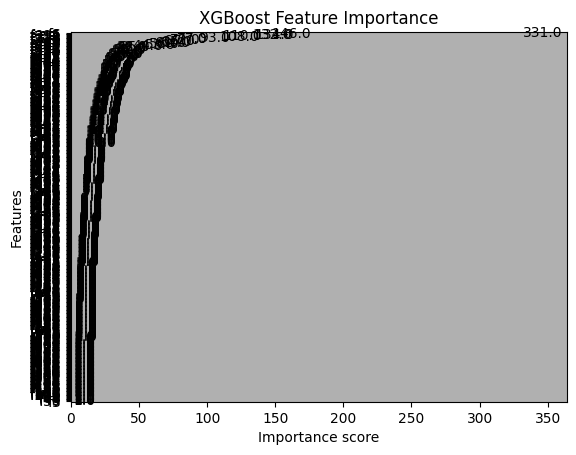

In [ ]:
xgb.plot_importance(model_xgb)
plt.title("XGBoost Feature Importance")
plt.show()

Hybrid Model

In [ ]:
# Predict scaled values
lstm_pred_scaled = model_lstm.predict(X_test_seq)
xgb_pred_scaled = model_xgb.predict(X_test_seq.reshape(X_test_seq.shape[0], -1))

# Inverse scale back to real traffic volume
lstm_pred = scaler_y.inverse_transform(lstm_pred_scaled)
xgb_pred = scaler_y.inverse_transform(xgb_pred_scaled.reshape(-1, 1))

y_actual = scaler_y.inverse_transform(y_test_seq)

print("Predictions shape: ")
print(f"LSTM: {lstm_pred.shape}")
print(f"XGBoost: {xgb_pred.shape}")

272/272 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
Predictions shape: 
LSTM: (8676, 1)
XGBoost: (8676, 1)


In [ ]:
hybrid_pred = (0.1 * lstm_pred) + (0.9 * xgb_pred.reshape(-1, 1))

In [ ]:
def evaluate_model(y_actual, lstm_pred, xgb_pred, hybrid_pred):
  results = []

  def calculate_metrics(y_actual, y_pred, model_name):
    rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
    mae = mean_absolute_error(y_actual, y_pred)
    mape = mean_absolute_percentage_error(y_actual, y_pred)
    r2 = r2_score(y_actual, y_pred)

    return {
        "Model": model_name,
        "RMSE": round(rmse, 5),
        "MAE": round(mae, 5),
        "MAPE": round(mape, 5),
        "R2": round(r2, 5)
    }

  results.append(calculate_metrics(y_actual, lstm_pred, "LSTM"))
  results.append(calculate_metrics(y_actual, xgb_pred, "XGBoost"))
  results.append(calculate_metrics(y_actual, hybrid_pred, "Hybrid"))

  return pd.DataFrame(results)

In [ ]:
results_df = evaluate_model(y_actual, lstm_pred, xgb_pred, hybrid_pred)
print(results_df)

     Model       RMSE        MAE     MAPE       R2
0     LSTM  539.04794  387.71340  0.19053  0.92564
1  XGBoost  412.65267  266.66860  0.11779  0.95642
2   Hybrid  411.94813  267.53478  0.11737  0.95657


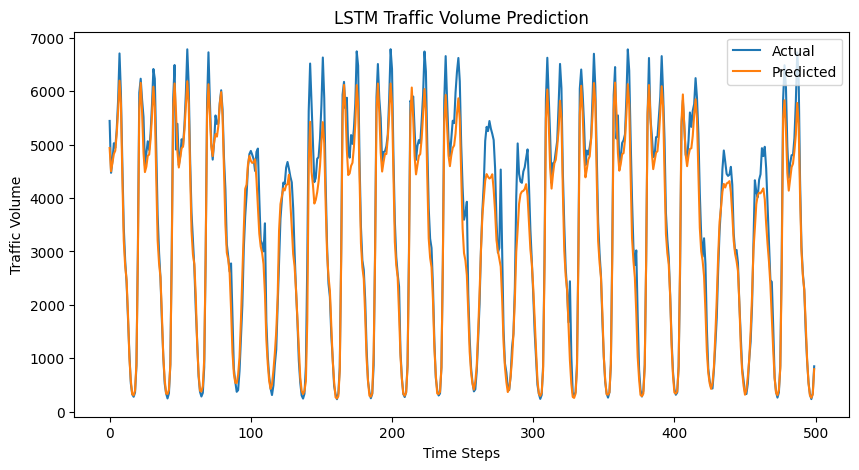

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(y_actual[:500], label='Actual')
plt.plot(hybrid_pred[:500], label='Predicted')
plt.title('LSTM Traffic Volume Prediction')
plt.xlabel('Time Steps')
plt.ylabel('Traffic Volume')
plt.legend()
plt.show()

In [ ]:
model_lstm.save("lstm.keras")